In [1]:
import os
from collections import defaultdict

import lifelines
import matplotlib.pyplot as plt
import matplotlib
import numpy
import pandas
import pickle
import time
import seaborn as sns

import immuw.clustering.clustering_utils as cimu
import tumorhood_analysis_utils as tau

# Zenodo-staged artifacts directory (portable replacement for the original
# research-infra absolute paths below; contents verified byte-identical).
ZENODO_PATH = '/raid/immucan/immuw/cellohood_artifacts/NSCLC_P1/'


# Number of enriched cellular neighborhood classes
CC_NB_OF_CLUSTERS = 23
ROI_TYPE_ANALYSIS = 'ALL'

CLUSTER_SELECTION_PATH = f'./NSCLC-Cello-v1-SD-100{CC_NB_OF_CLUSTERS}/'

VECTORIZER = lambda x: x.values.T ** 0.5
VECTORIZER_NAME = 'sqrt'
PANEL_1_CLUSTER_SELECTION_PATH = os.path.join(CLUSTER_SELECTION_PATH, f'p1_cs_result_{ROI_TYPE_ANALYSIS}_{VECTORIZER_NAME}.pickle')

# PREDICTION RELATED 
TYPE = 'sd'
PREDICTIONS_PATH = os.path.join(ZENODO_PATH, 'ALL_PLDA.100', 'predictions.npy')
PREDICTION_CLUSTER_COLUMN = 'Cellular Neighborhood'
CC_CLUSTER_NAME = 'tumorhood_neighborhood_cluster'

# IMAGE/SAMPLE RELATED 
ROI_COLUMN = 'image'
SAMPLE_COLUMN = 'sample_id'

CLINICAL_DATA_DF = os.path.join(ZENODO_PATH, 'nsclc_clinical_corrected.csv')


PANEL_1_FULL_CSV_FILEPATH = os.path.join(ZENODO_PATH, 'nsclc2_p1_25.df')

# MARKER RELATED
MARKERS = tau.PANEL_1_MARKER_NAMES
MARKERS_CLEAN = [
    'MPO',
    'H3',
    'SMA',
    'CD16',
    'CD38',
    'HLA-DR',
    'CD27',
    'CD15',
    'CD45RA',
    'CD163',
    'B2M',
    'CD20',
    'CD68',
    'Ido1',
    'CD3',
    'LAG3',
    'CD11c',
    'PD1',
    'PDGFRb',
    'CD7',
    'GrB',
    'PDL1',
    'TCF7',
    'CD45RO',
    'FOXP3',
    'ICOS',
    'CD8a',
    'CAIX',
    'CD33',
    'Ki67',
    'VISTA',
    'CD40',
    'CD4',
    'CD14',
    'ECad',
    'CD303',
    'CD206',
    'cl.PARP',
    'DNA1',
    'DNA2',
]

# Clinical Related:
CLINICAL_DATA_COLS_FOR_ANALYSIS = [
    'roman_simple_stage', 
    'stage_2-',
    'simple_histology',
    #'neo_adjuvant_treatment',
    'death', 
    'smoking_status',
    'gender',
    #'environmental_exposure',
    'TPS_score',
    'CPS_score',
    'tmb_class',
    'KRAS', 'TP53', 'EGFR', 'PIK3CA', 'ERBB2'
] 

# Additional Column names
DUMMY_COL_NAME = 'dummy'
CELLTYPE_COLNAME = 'celltypes'
CELLTYPE_PLOT_NAME = 'Cell type'
MARKER_PLOT_NAME = 'Marker'
ALL_PLOT_NAME = 'All'
ROI_CLUSTER_NAME = 'SG'

# Plotting
PLOTTING_DPI = 300
sns.set_context("paper", rc={"font.size": 6, "axes.titlesize":6,"axes.labelsize":6})  
plt.rcParams['legend.title_fontsize'] = 6
plt.rcParams['legend.fontsize'] = 6

matplotlib.font_manager.fontManager.addfont('/raid/immucan/immuw/Arial.ttf')  # if you need to add the font file
plt.rcParams['font.family'] = 'Arial'

## Cell type level data loading and preprocessing

In [2]:
cell_df = pandas.read_csv(PANEL_1_FULL_CSV_FILEPATH)

/tmp/ipykernel_56199/796832730.py:1: DtypeWarning: Columns (15,83,84) have mixed types. Specify dtype option on import or set low_memory=False.
  cell_df = pandas.read_csv(PANEL_1_FULL_CSV_FILEPATH)


In [3]:
# Marker ARCSINH x / 5 transformation
cell_df[MARKERS] =  cell_df[MARKERS].applymap(lambda x: numpy.arcsinh(x / 5.))

In [4]:
# Extra column for computations
cell_df[DUMMY_COL_NAME] = 1

## Prediction level loading

In [5]:
predictions = numpy.load(PREDICTIONS_PATH)

In [6]:
if TYPE == 'bag':
    cell_df[PREDICTION_CLUSTER_COLUMN] = cell_df[CC_CLUSTER_NAME].apply(lambda x: predictions[x])
elif TYPE == 'sd':
    cell_df[PREDICTION_CLUSTER_COLUMN] = predictions
else:
    raise ValueError('Unknown TYPE.')

## TLS / Tumor Core subselection

In [7]:
def roi_is_tls(image_name):
    return image_name[:-5].split('_')[-1] == '004'

In [8]:
TLS_CELL_SELECTOR = cell_df[ROI_COLUMN].apply(lambda x: roi_is_tls(x))
NON_TLS_CELL_SELECTOR = cell_df[ROI_COLUMN].apply(lambda x: not roi_is_tls(x))

In [9]:
TLS_CELL_SELECTOR.sum(), NON_TLS_CELL_SELECTOR.sum(), TLS_CELL_SELECTOR.sum() + NON_TLS_CELL_SELECTOR.sum()

(593052, 1495338, 2088390)

In [10]:
cell_df['ROI_index'] = cell_df[ROI_COLUMN].apply(lambda x:  x[:-5].split('_')[-1])

In [11]:
cell_df[cell_df['ROI_index'] == '004'].groupby('image').size()

image
IMMUcan_Batch20210701_LUNG_10018881-LUNG-VAR-TIS-01-IMC-01_004.tiff    2804
IMMUcan_Batch20210701_LUNG_10018882-LUNG-VAR-TIS-01-IMC-01_004.tiff    2580
IMMUcan_Batch20210701_LUNG_10018884-LUNG-VAR-TIS-01-IMC-01_004.tiff    3548
IMMUcan_Batch20210701_LUNG_10018885-LUNG-VAR-TIS-01-IMC-01_004.tiff    4279
IMMUcan_Batch20210701_LUNG_10018888-LUNG-VAR-TIS-01-IMC-01_004.tiff    2345
                                                                       ... 
IMMUcan_Batch20210921_LUNG_10041586-LUNG-VAR-TIS-01-IMC-01_004.tiff    3978
IMMUcan_Batch20210921_LUNG_10041587-LUNG-VAR-TIS-01-IMC-01_004.tiff    3266
IMMUcan_Batch20210921_LUNG_10041589-LUNG-VAR-TIS-01-IMC-01_004.tiff    3680
IMMUcan_Batch20210921_LUNG_10041591-LUNG-VAR-TIS-01-IMC-01_004.tiff    3339
IMMUcan_Batch20210921_LUNG_10041592-LUNG-VAR-TIS-01-IMC-01_004.tiff    2964
Length: 172, dtype: int64

In [12]:
cell_df[cell_df['ROI_index'] != '004'].groupby('image').size()

image
IMMUcan_Batch20210701_LUNG_10018881-LUNG-VAR-TIS-01-IMC-01_001.tiff    3050
IMMUcan_Batch20210701_LUNG_10018881-LUNG-VAR-TIS-01-IMC-01_002.tiff    2765
IMMUcan_Batch20210701_LUNG_10018881-LUNG-VAR-TIS-01-IMC-01_003.tiff    2381
IMMUcan_Batch20210701_LUNG_10018882-LUNG-VAR-TIS-01-IMC-01_001.tiff    2743
IMMUcan_Batch20210701_LUNG_10018882-LUNG-VAR-TIS-01-IMC-01_002.tiff    2610
                                                                       ... 
IMMUcan_Batch20210921_LUNG_10041591-LUNG-VAR-TIS-01-IMC-01_002.tiff    3216
IMMUcan_Batch20210921_LUNG_10041591-LUNG-VAR-TIS-01-IMC-01_003.tiff    2226
IMMUcan_Batch20210921_LUNG_10041592-LUNG-VAR-TIS-01-IMC-01_001.tiff    3620
IMMUcan_Batch20210921_LUNG_10041592-LUNG-VAR-TIS-01-IMC-01_002.tiff    2868
IMMUcan_Batch20210921_LUNG_10041592-LUNG-VAR-TIS-01-IMC-01_003.tiff    3279
Length: 569, dtype: int64

In [13]:
if ROI_TYPE_ANALYSIS == 'TUMOR':
    cell_df = cell_df[NON_TLS_CELL_SELECTOR]
elif ROI_TYPE_ANALYSIS == 'TLS':
    cell_df = cell_df[TLS_CELL_SELECTOR]
elif ROI_TYPE_ANALYSIS == 'ALL':
    cell_df = cell_df
else:
    raise ValueError('Unknown ROI type analysis')

## Cell type related preparation:

In [14]:
celltype_counts = pandas.pivot_table(
    cell_df, 
    values=DUMMY_COL_NAME, 
    index=[PREDICTION_CLUSTER_COLUMN],
    columns=[CELLTYPE_COLNAME],
    aggfunc="sum",
).fillna(0)

In [15]:
celltype_percentages = (celltype_counts.T / celltype_counts.sum(axis=1)).T
celltype_percentages.columns.name = CELLTYPE_PLOT_NAME

In [16]:
celltypes = list(celltype_percentages.columns)

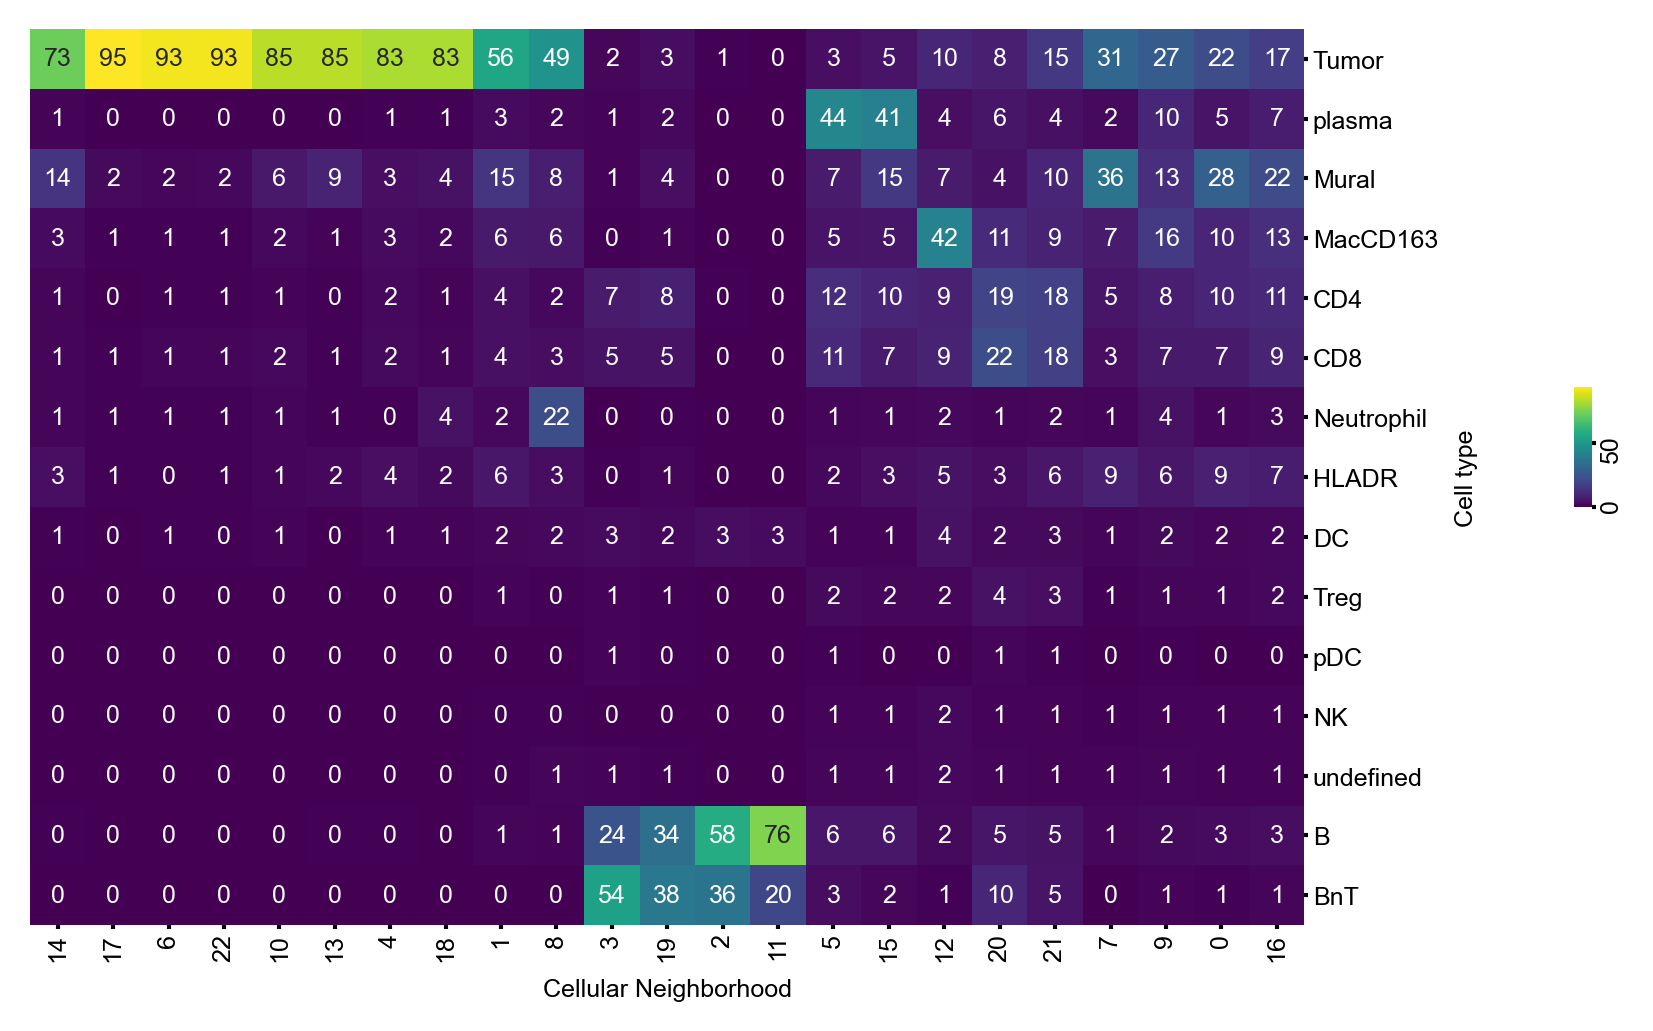

In [17]:
celltype_clustermap = sns.clustermap(
    celltype_percentages[celltypes].T * 100, 
    annot=True,
    #row_colors=celltypes_color_df,
    fmt='.0f',
    cmap='viridis',
    cbar_pos=(1.05, 0.4, 0.01, 0.1),
    annot_kws={"size": 6},
    cbar_kws={'label': ''}
)

#celltype_clustermap.ax_cbar.set_xlabel(f'{CELLTYPE_PLOT_NAME} percentage', labelpad=0, size=6)

celltype_clustermap.ax_cbar.tick_params(labelsize=6, size=1, pad=1, rotation=90)
celltype_clustermap.ax_row_dendrogram.set_visible(False)
celltype_clustermap.ax_col_dendrogram.set_visible(False)

celltype_clustermap.ax_heatmap.set_yticklabels(celltype_clustermap.ax_heatmap.get_yticklabels(), size=6)
celltype_clustermap.ax_heatmap.xaxis.set_tick_params(size=1, left=True, pad=1)
celltype_clustermap.ax_heatmap.yaxis.set_tick_params(size=1, pad=1, rotation=0)
celltype_clustermap.ax_heatmap.set_xticklabels(celltype_clustermap.ax_heatmap.get_xticklabels(), size=6, rotation=90)
#celltype_clustermap.ax_row_colors.set_xticklabels(celltype_clustermap.ax_row_colors.get_xticklabels(), size=6)
#celltype_clustermap.ax_row_colors.xaxis.set_tick_params(size=1, pad=1)

celltype_clustermap.fig.set_dpi(PLOTTING_DPI)
celltype_clustermap.fig.set_size_inches((6, 4))

## Marker analysis

### Cell type level:
For each marker compute the average marker expression for a given cell type:

In [18]:
marker_to_celltype_dfs = {}


for marker in MARKERS:
    marker_to_celltype_dfs[marker] = pandas.pivot_table(
    cell_df, 
    values=marker, 
    index=[PREDICTION_CLUSTER_COLUMN],
    columns=[CELLTYPE_COLNAME],
    aggfunc='mean',
).fillna(0)

Now - let us transpose this dictionary to cell type to marker df:

In [19]:
marker_ct_ipc = numpy.stack([
    marker_df.values
    for marker_df in marker_to_celltype_dfs.values()
])

celltype_to_marker_dfs = {
    ct: pandas.DataFrame(
        marker_ct_ipc[:, :, ct_ind],
        index=MARKERS,
    )
    for ct_ind, ct in enumerate(celltypes)
}

Now - let's rename the markers to their clean names:

In [20]:
celltype_to_marker_dfs_clean = {}


for celltype, cdf in celltype_to_marker_dfs.items():
    cdf_clean = cdf.copy()
    cdf_clean[MARKER_PLOT_NAME] = MARKERS_CLEAN
    cdf_clean.set_index(MARKER_PLOT_NAME, inplace=True),
    celltype_to_marker_dfs_clean[celltype] = cdf_clean

## All marker analysis:

Now let's compute the overall marker distribution across all cells:

In [21]:
all_markers_distribution = cell_df.groupby([PREDICTION_CLUSTER_COLUMN]).mean()[MARKERS]
all_markers_distribution -= all_markers_distribution.mean()
all_markers_distribution /= all_markers_distribution.std()
all_markers_distribution.columns = MARKERS_CLEAN

celltype_to_marker_dfs_clean[ALL_PLOT_NAME] = all_markers_distribution.T

/tmp/ipykernel_56199/762203048.py:1: FutureWarning: The default value of numeric_only in DataFrameGroupBy.mean is deprecated. In a future version, numeric_only will default to False. Either specify numeric_only or select only columns which should be valid for the function.
  all_markers_distribution = cell_df.groupby([PREDICTION_CLUSTER_COLUMN]).mean()[MARKERS]


Now let's display the all marker distributions:

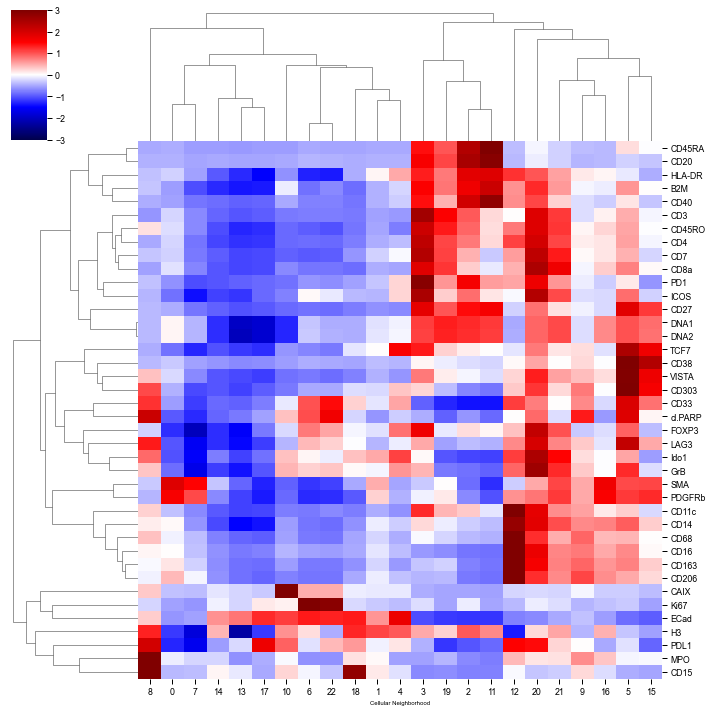

In [22]:
sns.clustermap(all_markers_distribution.T, center=0, cmap='seismic', vmin=-3, vmax=3)

Now - let's visualize the Cellohood Neighobrhoods with average markers.

Let's start with providing some handy tools:
- marker colormap:

In [23]:
marker_color_norm = matplotlib.colors.Normalize(vmin=-2, vmax=2)
marker_cmap = plt.get_cmap('coolwarm')

marker_sm = matplotlib.cm.ScalarMappable(norm=marker_color_norm, cmap=marker_cmap)

and a code to transform values to vectors:

In [24]:
def transform_vec_to_colors(
    vec,
    colors,
    standarize=True,
    display=None,
    permute=None,
    ignore_color=(160 / 255, 160 / 255, 160 / 255),
):
    if standarize:
        display = display if display is not None else numpy.arange(len(vec))
        vec = vec.copy()
        vec = vec - numpy.mean(vec[display])
        vec = vec / numpy.std(vec[display])
    result = [
        colors.to_rgba(x)
        for x in vec
    ]
    if display is not None:
        new_result = []
        for ind_, result_col in enumerate(result):
            current_color = list(result_col)
            if ind_ in display:
                pass 
            else:
                current_color = ignore_color
            new_result.append(current_color)
            
        result = new_result
    if permute:
        result = [
            result[i]
            for i in permute
        ]
    return result

Now let's transform average markers across all cells to colors:

In [25]:
all_colors_dict = {
    f'{marker}': transform_vec_to_colors( 
        vec=celltype_to_marker_dfs_clean[ALL_PLOT_NAME].loc[marker],
        colors=marker_sm,
    )
    for marker in MARKERS_CLEAN
}

all_colors_df = pandas.DataFrame(all_colors_dict)

and visualize CC clusters with average marker distributions:

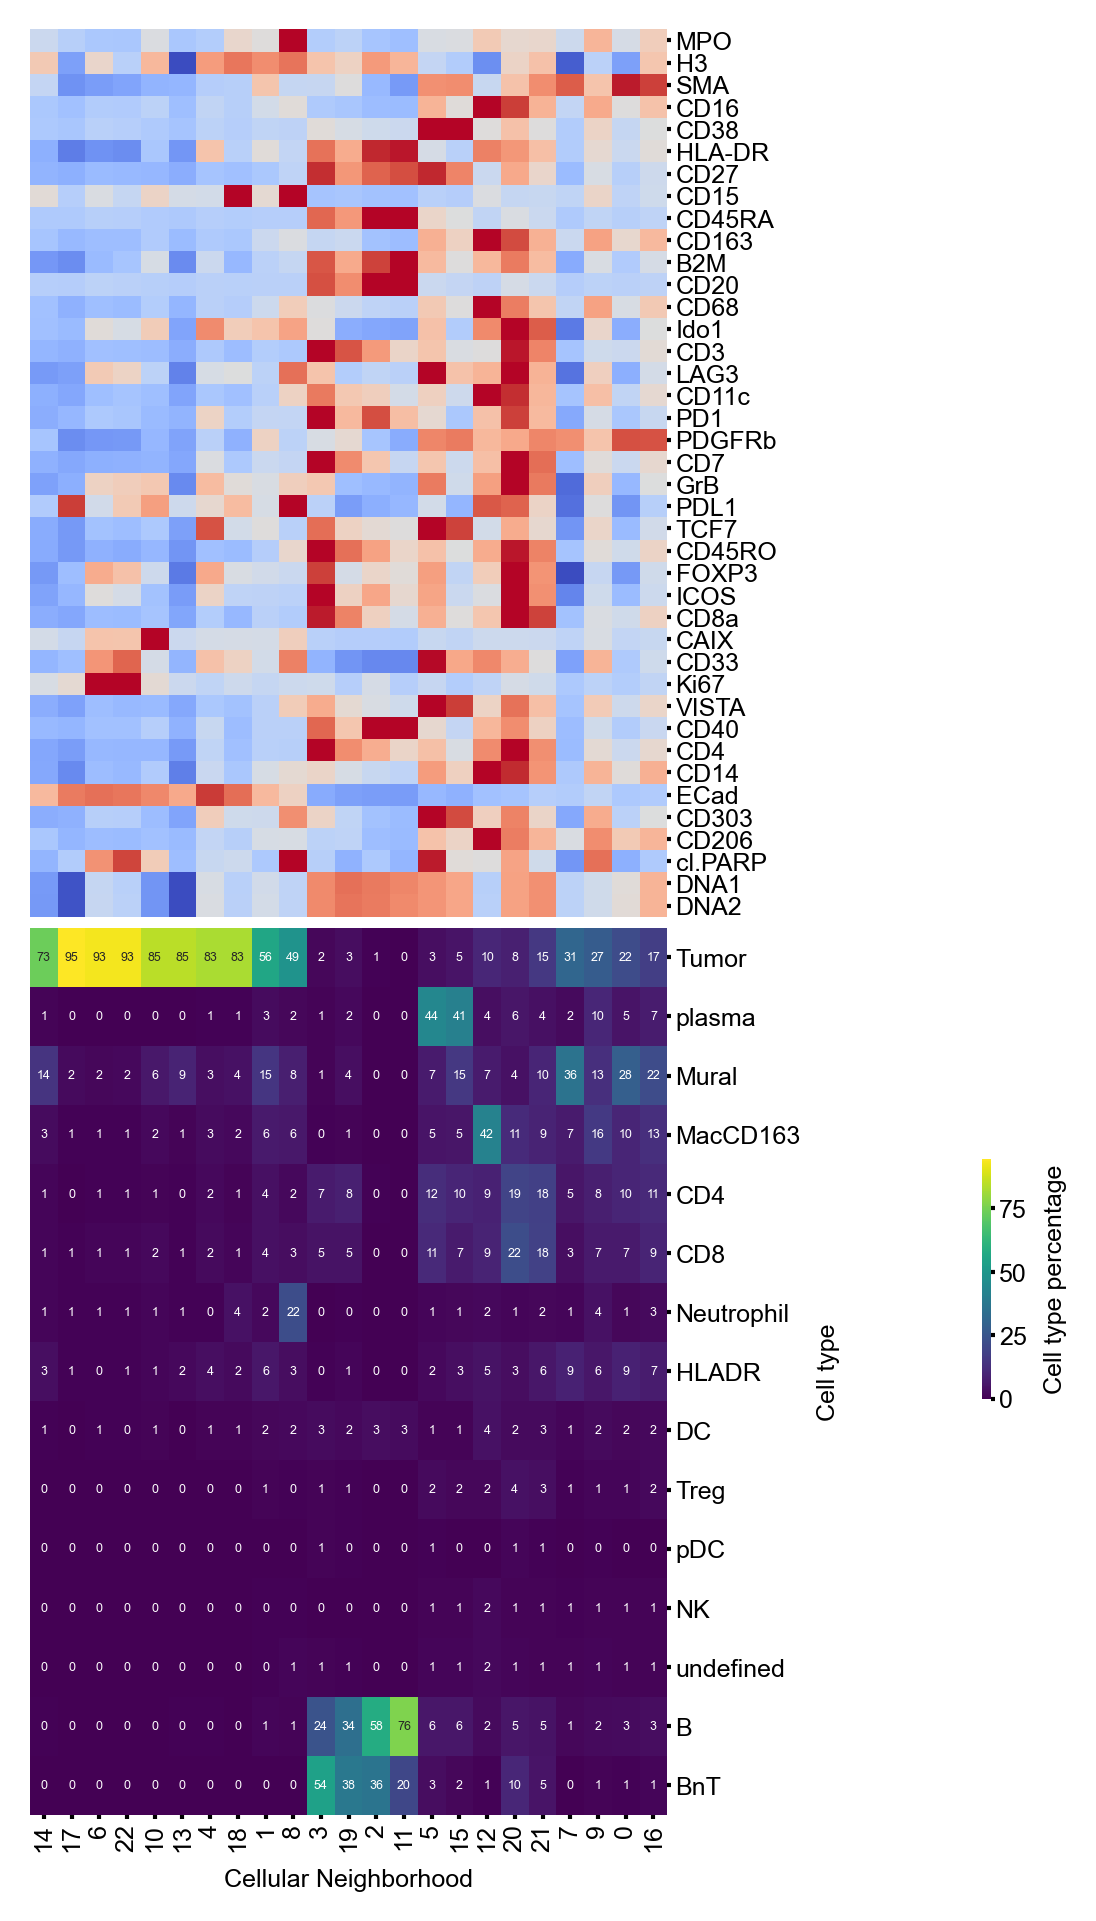

In [26]:
celltype_with_all_markers_clustermap = sns.clustermap(
    celltype_percentages[celltypes].T * 100, 
    annot=True,
    #row_colors=celltypes_color_df,
    fmt='.0f',
    cmap='viridis',
    cbar_pos=(1.25, 0.225, 0.01, 0.1),
    col_colors=all_colors_df,
    annot_kws={'size': 3},
    yticklabels=1,
    colors_ratio=(0.01, 0.01),
    cbar_kws={'label': f'{CELLTYPE_PLOT_NAME} percentage'}
)

celltype_with_all_markers_clustermap.ax_cbar.tick_params(labelsize=6, size=1, pad=1)
celltype_with_all_markers_clustermap.ax_row_dendrogram.set_visible(False)
celltype_with_all_markers_clustermap.ax_col_dendrogram.set_visible(False)

celltype_with_all_markers_clustermap.ax_heatmap.set_yticklabels(
    celltype_with_all_markers_clustermap.ax_heatmap.get_yticklabels(), size=6)
celltype_with_all_markers_clustermap.ax_heatmap.xaxis.set_tick_params(size=1, left=True, pad=1)
celltype_with_all_markers_clustermap.ax_heatmap.yaxis.set_tick_params(size=1, pad=1, rotation=0)
celltype_with_all_markers_clustermap.ax_heatmap.set_xticklabels(
    celltype_with_all_markers_clustermap.ax_heatmap.get_xticklabels(), size=6, rotation=90)

#celltype_with_all_markers_clustermap.ax_row_colors.set_xticklabels(
#    celltype_with_all_markers_clustermap.ax_row_colors.get_xticklabels(), size=6
#)
celltype_with_all_markers_clustermap.ax_col_colors.set_yticklabels(
    celltype_with_all_markers_clustermap.ax_col_colors.get_yticklabels(), size=6
)
celltype_with_all_markers_clustermap.ax_col_colors.yaxis.set_tick_params(size=1, pad=1)

celltype_with_all_markers_clustermap.fig.set_dpi(PLOTTING_DPI)
celltype_with_all_markers_clustermap.fig.set_size_inches((3, 8))


## Density analysis

In [27]:
cc_densities = cell_df.groupby(
    [PREDICTION_CLUSTER_COLUMN, CC_CLUSTER_NAME]
).size().groupby(PREDICTION_CLUSTER_COLUMN).mean()

## Marker Cluster analysis for cell types

Now let's analyse the marker expression for cells within certain Cellohood Clusters:

In [28]:
celltypes_display_percentage = defaultdict(lambda: 0.1)
celltypes_display_percentage['Tumor'] = 0.15
celltypes_display_percentage['CD4'] = 0.05
celltypes_display_percentage['CD8'] = 0.05
#celltypes_display_percentage['Mural'] = 0.14

In [29]:
celltypes_to_marker_to_show = {
    'B': ['CD40', 'CD20', 'CD45RA', 'CD45RO'],
    'CD4': ['CD45RA', 'CD45RO'],
    'CD8': ['PD1', 'GrB', 'CD45RA', 'CD45RO'],
    'MacCD163': [
        'Ido1', 'PDL1', 'CD14', 'CD68', 'CD206', 'CD11c'],
    'Mural': ['SMA', 'PDGFRb'],
    'Tumor': ['DNA1', 'H3', 'ECad', 'cl.PARP', 'CD15', 'CAIX',
        'B2M', 'TCF7', 'PDL1', 'Ki67'],
    'All': ['VISTA', 'ICOS', 'LAG3']
}

In [30]:
celltypes_cc_display = {
    ct: [
        ind_ 
        for ind_, cc_ in enumerate(celltype_percentages[ct] > celltypes_display_percentage[ct])
        if cc_
    ]
    for ct in celltypes_to_marker_to_show
    if ct in celltype_percentages.columns
}

In [31]:
cc_colors_dict = {}
for ct, markers in celltypes_to_marker_to_show.items():
    for marker in markers:
        cc_colors_dict[f'{ct}: {marker}'] = transform_vec_to_colors( 
                vec=celltype_to_marker_dfs_clean[ct].loc[marker],
                colors=marker_sm,
                display=celltypes_cc_display[ct] if ct in celltypes_cc_display else None,
            )


cc_marker_ct_colors = pandas.DataFrame(cc_colors_dict)

cc_marker_ct_colors['All: Cell density'] = transform_vec_to_colors( 
        vec=cc_densities,
        colors=marker_sm,
)

In [32]:
meta_cluster_dict = {
    'PURE_TUMOR': [13, 6, 22, 17, 4, 10, 18],
    'NEUTROPHIL': [8],
    'MURAL': [14, 1, 7, 0, 16],
    'INFILTRATION': [21, 9, 20],
    'MAC': [12],
    'PLASMA': [5, 15],
    'TLS': [3, 19, 2, 11],
}

In [33]:
META_CLUSTER_PERM = []
meta_cluster_colors = []
meta_cluster_names = []


for mc, cls_ in meta_cluster_dict.items():
        for index_ in cls_:
            meta_cluster_colors.append(tau.META_CLUSTER_TO_COLOR[mc])
            META_CLUSTER_PERM.append(index_)
            meta_cluster_names.append(mc)

In [34]:
META_CLUSTER_PERM

[13,
 6,
 22,
 17,
 4,
 10,
 18,
 8,
 14,
 1,
 7,
 0,
 16,
 21,
 9,
 20,
 12,
 5,
 15,
 3,
 19,
 2,
 11]

In [35]:
IMMU_METAS_CLEAN = [
    'Pure Tumor',
    'Neutrophil-enriched',
    'Mural-enriched',
    'Plasma cell-enriched',
    'Infiltration',
    'Mac-enriched',
    'CD20+',
]

IMMU_METAS = [
    'PURE_TUMOR', 'NEUTROPHIL', 'MURAL', 'PLASMA', 'INFILTRATION', 'MAC', 'TLS'
]

In [36]:
IMMU_METAS

['PURE_TUMOR', 'NEUTROPHIL', 'MURAL', 'PLASMA', 'INFILTRATION', 'MAC', 'TLS']

In [37]:
cc_marker_ct_colors['CN Class'] = numpy.array(meta_cluster_colors)[numpy.argsort(META_CLUSTER_PERM)]

/tmp/ipykernel_56199/925969494.py:94: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()
/tmp/ipykernel_56199/925969494.py:94: UserWarning: Tight layout not applied. tight_layout cannot make axes width small enough to accommodate all axes decorations
  plt.tight_layout()


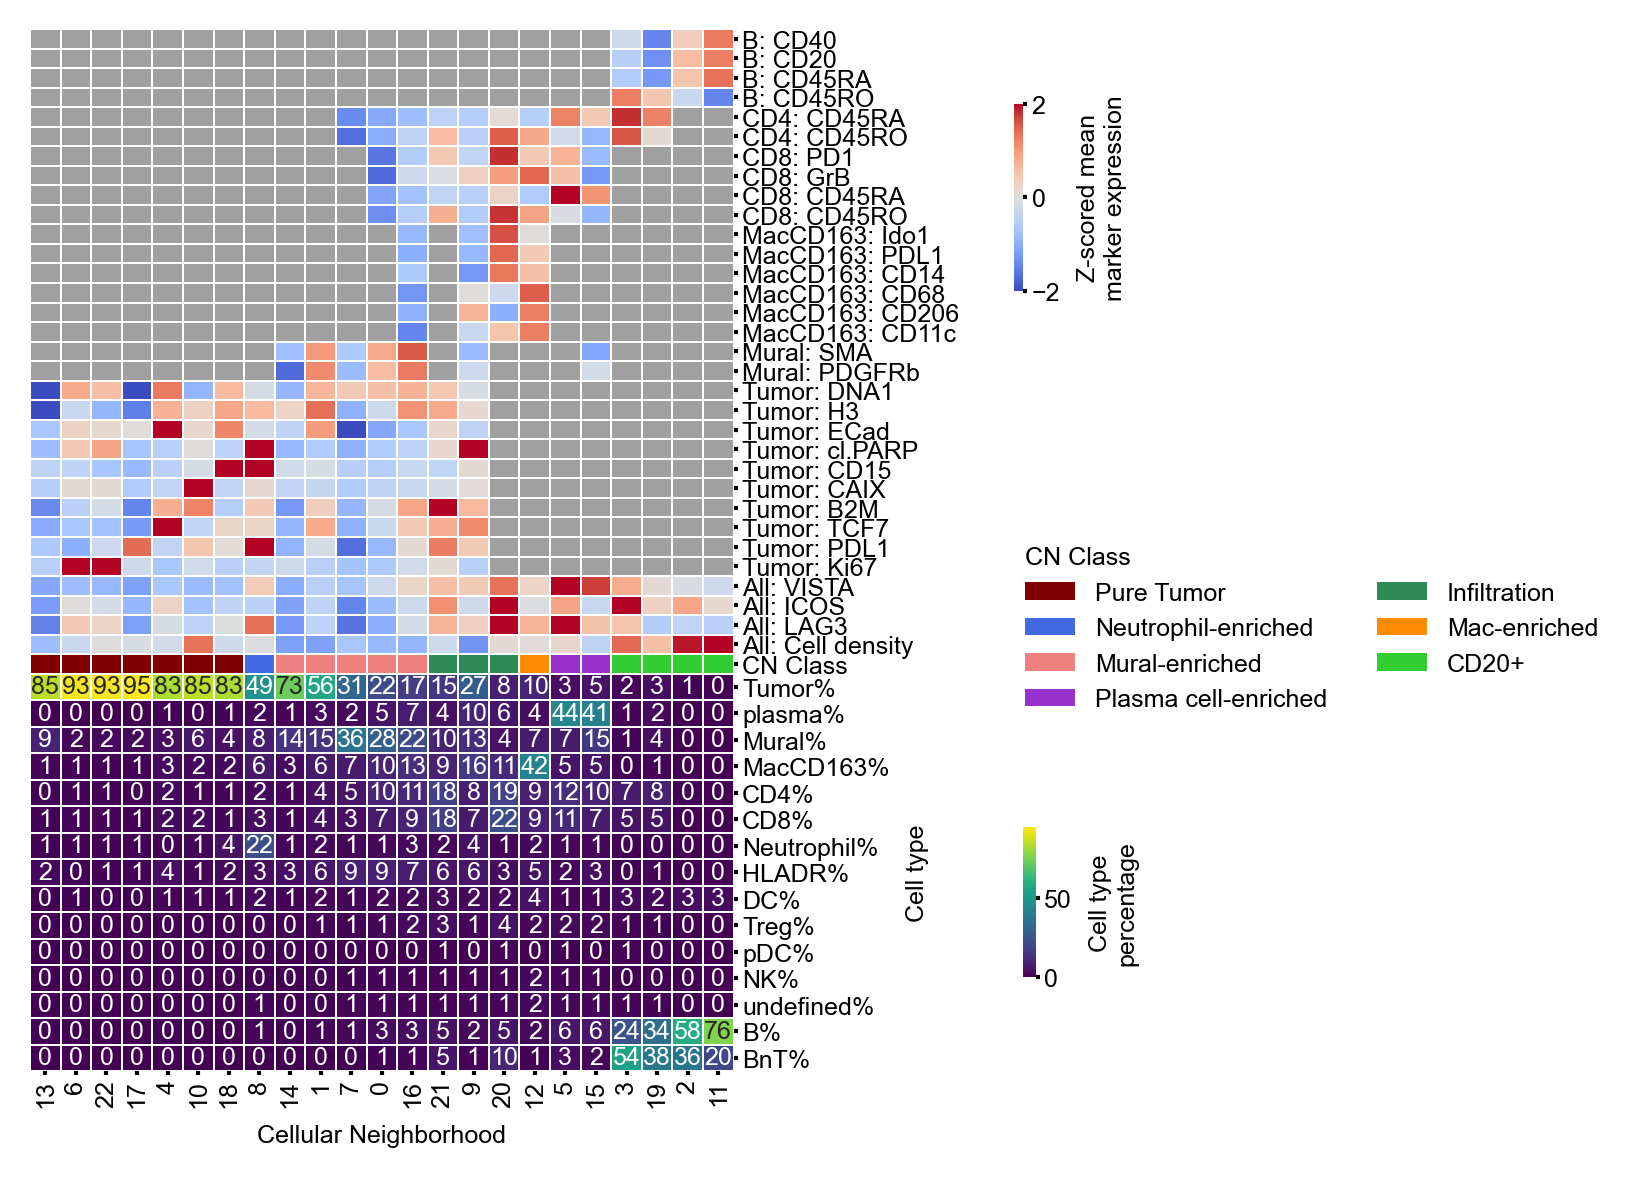

In [38]:
COLORBARS_SHIFT = 0.92

cc_abundance_std_argsort = (-celltype_percentages['Tumor'].values).argsort()

celltype_clustermap = sns.clustermap(
    (celltype_percentages[celltypes].T * 100)[META_CLUSTER_PERM], 
    annot=True,
    col_cluster=False,
    fmt='.0f',
    cmap='viridis',
    figsize=(5, 6),
    col_colors=cc_marker_ct_colors,
    #row_colors=[class_to_color[celltype_to_class[ct]] for ct in numpy.array(celltypes)],
    colors_ratio=0.015,
    yticklabels=True,
    xticklabels=META_CLUSTER_PERM,
    linewidth=0.003,
    annot_kws={"size": 6},
    cbar_pos=[COLORBARS_SHIFT + 0.05, 0.15, 0.01, .1],
    cbar_kws={'label': 'Cell type\npercentage'}
)


#handles = [Patch(facecolor=class_to_color[name]) for name in class_to_color]
#plt.legend(
#    handles, 
#    class_to_color, 
#    title=' Cell type Metatype',
#    bbox_to_anchor=(0.17, 0.53), 
#    bbox_transform=plt.gcf().transFigure,
#    frameon=False,
#    fontsize=6,
#)

celltype_clustermap.ax_col_dendrogram.set_visible(False)

cb_ax = celltype_clustermap.fig.add_axes([COLORBARS_SHIFT, .27, .05, .8])
cb_ax.imshow([[0, 1]])
cb_ax.set_visible(False)

cbar = celltype_clustermap.fig.colorbar(
    marker_sm, 
    drawedges=False,
    #bbox_to_anchor=(1, 0.5),
    label='Z-scored mean\nmarker expression',
    ax=cb_ax,
    #panchor=(1.5, 0.5),
    #anchor=(1.5, 0.5),
)

cbar.outline.set_visible(False)
cbar.ax.tick_params(labelsize=6, size=1, pad=1)

meta_handles = [matplotlib.patches.Patch(facecolor=tau.META_CLUSTER_TO_COLOR[name]) for name in IMMU_METAS]

meta_legend = plt.legend(
    meta_handles, 
    IMMU_METAS_CLEAN, 
    title='CN Class',
    bbox_to_anchor=(1.45, .4525), 
    bbox_transform=plt.gcf().transFigure,
    frameon=False,
    ncols=2,
    fontsize=6,
    alignment='left',
    markerfirst=True,
)
plt.gcf().add_artist(meta_legend)

celltype_clustermap.ax_cbar.tick_params(labelsize=6, size=1, pad=1)
celltype_clustermap.ax_row_dendrogram.set_visible(False)
celltype_clustermap.ax_col_dendrogram.set_visible(False)

celltype_clustermap.ax_heatmap.set_yticklabels(
    [tick.get_text() + '%' 
     for tick in celltype_clustermap.ax_heatmap.get_yticklabels()
    ], size=6)
celltype_clustermap.ax_heatmap.xaxis.set_tick_params(size=1, left=True, pad=1)
celltype_clustermap.ax_heatmap.yaxis.set_tick_params(size=1, pad=1)
celltype_clustermap.ax_heatmap.set_xticklabels(celltype_clustermap.ax_heatmap.get_xticklabels(), size=6, rotation=90)
celltype_clustermap.ax_col_colors.set_yticklabels(celltype_clustermap.ax_col_colors.get_yticklabels(), size=6)
celltype_clustermap.ax_col_colors.yaxis.set_tick_params(size=1, pad=1)

ax_row_colors = celltype_clustermap.ax_row_colors
ax_col_colors = celltype_clustermap.ax_col_colors
col_box = ax_col_colors.get_position()

box_heatmap = celltype_clustermap.ax_heatmap.get_position()
ax_col_colors.set_position([col_box.x0, box_heatmap.y1, col_box.width, col_box.height])


celltype_clustermap.fig.set_dpi(300)
celltype_clustermap.fig.set_size_inches((4.15, 5))
plt.tight_layout()

In [39]:
ct_clean_names = [
    'B',
    'BnT',
    'CD4',
    'CD8',
    'DC',
    'HLADR',
    'MacCD163',
    'Mural',
    'NK',
    'Neutrophil',
    'T-reg',
    'Tumor',
    'pDC',
    'Plasma cell',
    'Undefined',
]

(0.0, 1.0, 0.0, 1.0)

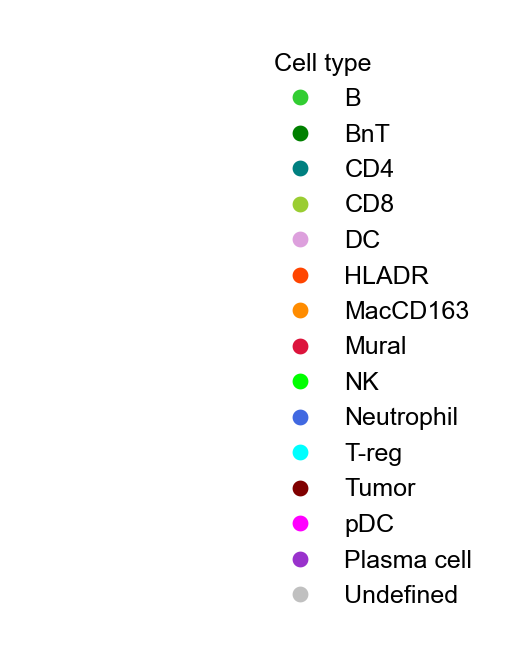

In [40]:
plt.figure(figsize=(2, 2), dpi=300)
ct_handles = [
    matplotlib.lines.Line2D(
        [0], [0],
        marker='o',
        color='w',
        markerfacecolor=color,
    ) for color in tau.PANEL_1_CELL_TYPE_TO_COLOR.values()]

meta_legend = plt.legend(
    ct_handles, 
    ct_clean_names, 
    title='Cell type',
    frameon=False,
    ncols=1,
    fontsize=6,
    alignment='left',
    markerfirst=True,
)

plt.axis('off')

(0.0, 1.0, 0.0, 1.0)

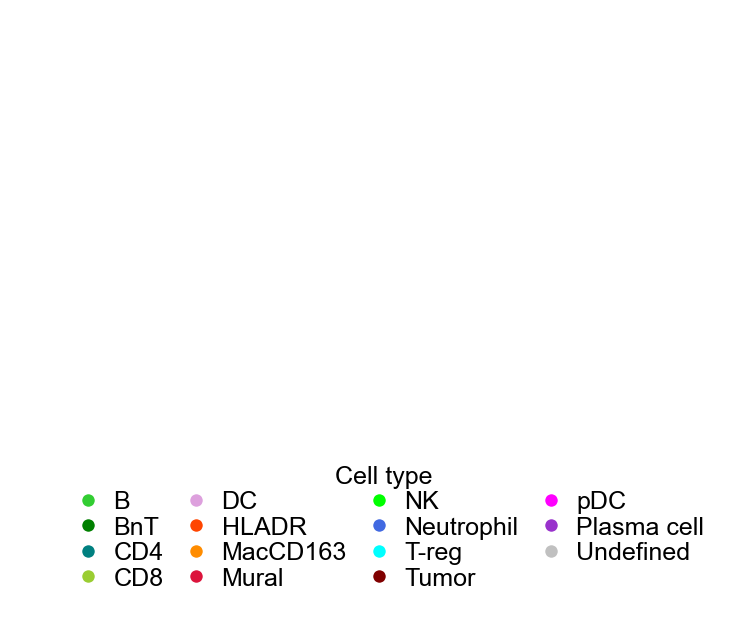

In [41]:
plt.figure(figsize=(2, 2), dpi=300)
ct_handles = [
    matplotlib.lines.Line2D(
        [0], [0],
        marker='o',
        color='w',
        markerfacecolor=color,
        markersize=4,
    ) for color in tau.PANEL_1_CELL_TYPE_TO_COLOR.values()]

meta_legend = plt.legend(
    ct_handles, 
    ct_clean_names, 
    title='Cell type',
    frameon=False,
    ncols=4,
    fontsize=6,
    #alignment='left',
    bbox_to_anchor=(0.05, -0.1),
    loc='center left',
    labelspacing=0.1,
    columnspacing=0.3,
    handletextpad=0.01,
    borderaxespad=0.,
    markerfirst=True,
)

plt.axis('off')

In [42]:
cell_df.groupby('image').size().shape

(741,)

(0.0, 1.0, 0.0, 1.0)

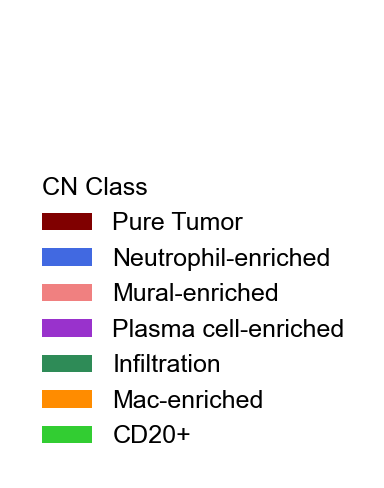

In [43]:
plt.figure(figsize=(1,1), dpi=300)
meta_legend = plt.legend(
    meta_handles, 
    IMMU_METAS_CLEAN, 
    title='CN Class',
    bbox_to_anchor=(1.45, .4525), 
    frameon=False,
    ncols=1,
    fontsize=6,
    alignment='left',
    markerfirst=True,
)
plt.axis('off')

Tumor


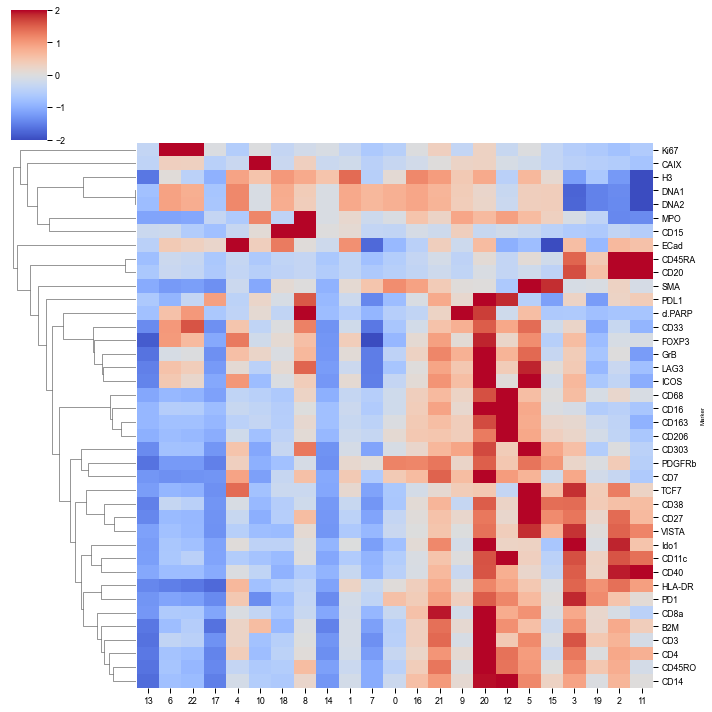

In [44]:
for ct in ['Tumor']:
    print(ct)
    sns.clustermap(
        celltype_to_marker_dfs_clean[ct].loc[MARKERS_CLEAN][META_CLUSTER_PERM], 
        yticklabels=MARKERS_CLEAN,
        z_score=0,
        center=0,
        cmap='coolwarm',
        col_cluster=False,
        vmin=-2,
        vmax=2,
    )
    plt.show()

In [45]:
cc_tls_counts = pandas.pivot_table(
    cell_df[TLS_CELL_SELECTOR], 
    values=DUMMY_COL_NAME, 
    index=[PREDICTION_CLUSTER_COLUMN],
    columns=['image'],
    aggfunc="sum",
).fillna(0).T 

In [46]:
cc_tls_counts = pandas.melt(cc_tls_counts)

In [47]:
cc_tumor_counts = pandas.pivot_table(
    cell_df[NON_TLS_CELL_SELECTOR], 
    values=DUMMY_COL_NAME, 
    index=[PREDICTION_CLUSTER_COLUMN],
    columns=['image'],
    aggfunc="sum",
).fillna(0).T 

In [48]:
cc_tumor_counts = pandas.melt(cc_tumor_counts)

In [49]:
cc_tumor_counts

,Cellular Neighborhood,value
0,0,188.0
1,0,226.0
2,0,182.0
3,0,267.0
4,0,377.0
...,...,...
13082,22,768.0
13083,22,431.0
13084,22,1534.0
13085,22,290.0


In [50]:
cc_tls_counts['Source'] = 'TLS'
cc_tumor_counts['Source'] = 'Tumor'

full_cc_counts = pandas.concat([cc_tls_counts, cc_tumor_counts])

In [51]:
import scipy

ttest_ps = []


for cl_ in range(CC_NB_OF_CLUSTERS):
    current_cc_counts = full_cc_counts[full_cc_counts[PREDICTION_CLUSTER_COLUMN] == cl_]
    current_tls_cc_counts = current_cc_counts[current_cc_counts['Source'] == 'TLS']
    current_tumor_cc_counts = current_cc_counts[current_cc_counts['Source'] == 'Tumor']
    current_test = scipy.stats.ttest_ind(
        current_tls_cc_counts['value'],
        current_tumor_cc_counts['value'],
        alternative='greater',
        equal_var=False,
    )
    ttest_ps.append(current_test.pvalue)

In [52]:
gb_avg_val = full_cc_counts.groupby(['Source', PREDICTION_CLUSTER_COLUMN])['value'].median()

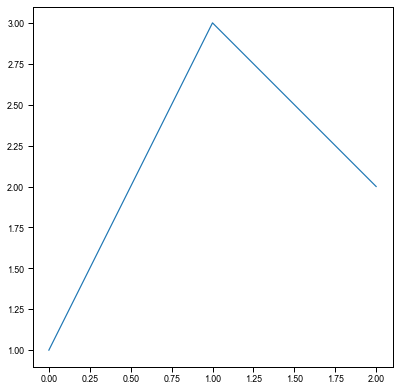

In [53]:
def set_size(w,h, ax=None):
    """ w, h: width, height in inches """
    if not ax: ax=plt.gca()
    l = ax.figure.subplotpars.left
    r = ax.figure.subplotpars.right
    t = ax.figure.subplotpars.top
    b = ax.figure.subplotpars.bottom
    figw = float(w)/(r-l)
    figh = float(h)/(t-b)
    ax.figure.set_size_inches(figw, figh)
          
fig, ax=plt.subplots()

ax.plot([1,3,2])

set_size(5,5)

plt.show()

/tmp/ipykernel_56199/1914999564.py:28: UserWarning: FixedFormatter should only be used together with FixedLocator
  _ = tls_tumor_box.yaxis.set_ticklabels(


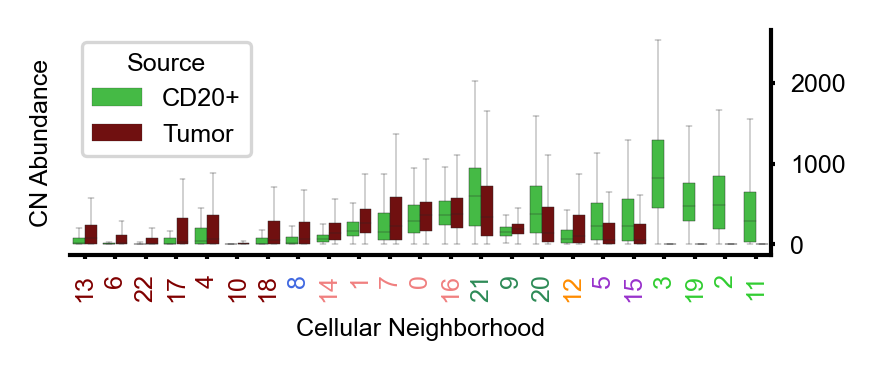

In [54]:
ps_argsort = numpy.argsort(ttest_ps)
ps_argsort = META_CLUSTER_PERM

n_ticks = len(ps_argsort)
width_per_tick = 2.3380539306104526 / 23  # width in inches per tick
total_width = n_ticks * width_per_tick

plt.figure(figsize=(total_width, 0.9), dpi=300)


tls_tumor_box = sns.boxplot(
    data=full_cc_counts, 
    x=PREDICTION_CLUSTER_COLUMN, 
    y='value', 
    hue='Source',
    linewidth=0.1,
    fliersize=0.1,
    order=ps_argsort,
    palette={'TLS': 'limegreen', 'Tumor': 'maroon'},
    #width=0.6,
    showfliers=False,
)
tls_tumor_box.xaxis.set_tick_params(size=1, rotation=90)
tls_tumor_box.yaxis.set_tick_params(size=1, rotation=0)
_ = tls_tumor_box.xaxis.set_ticklabels(
    tls_tumor_box.xaxis.get_ticklabels(), size=6,
)
_ = tls_tumor_box.yaxis.set_ticklabels(
    tls_tumor_box.yaxis.get_ticklabels(), size=6,
)

tls_tumor_box.get_children()[-2].get_texts()[0].set_text('CD20+')


for ind_, tick in enumerate(tls_tumor_box.get_xticklabels()):
    tick.set_color(meta_cluster_colors[numpy.array(META_CLUSTER_PERM).argsort()[ps_argsort[ind_]]])

tls_tumor_box.spines['top'].set_visible(False)
tls_tumor_box.spines['left'].set_visible(False)
tls_tumor_box.set_ylabel('CN Abundance')

tls_tumor_box.yaxis.tick_right()


set_size(2.3380539306104526, 0.75, tls_tumor_box)

/tmp/ipykernel_56199/1234660456.py:30: UserWarning: FixedFormatter should only be used together with FixedLocator
  _ = tls_tumor_box.yaxis.set_ticklabels(


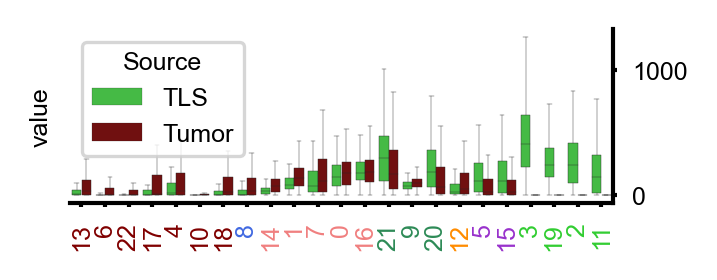

In [55]:
n_ticks = len(ps_argsort)
width_per_tick = 2.3380539306104526 / 23  # width in inches per tick
total_width = n_ticks * width_per_tick

# Create figure with calculated width
fig = plt.figure(dpi=300)
fig.set_size_inches(total_width, 1)  # 1 inch height, width based on ticks

# Your existing code here
tls_tumor_box = sns.boxplot(
    data=full_cc_counts, 
    x=PREDICTION_CLUSTER_COLUMN, 
    y='value', 
    hue='Source',
    linewidth=0.1,
    fliersize=0.1,
    order=ps_argsort,
    palette={'TLS': 'limegreen', 'Tumor': 'maroon'},
    showfliers=False,
)

# Adjust the bottom margin to make sure labels fit
plt.subplots_adjust(bottom=0.3)

tls_tumor_box.xaxis.set_tick_params(size=1, rotation=90)
tls_tumor_box.yaxis.set_tick_params(size=1, rotation=0)
_ = tls_tumor_box.xaxis.set_ticklabels(
    tls_tumor_box.xaxis.get_ticklabels(), size=6,
)
_ = tls_tumor_box.yaxis.set_ticklabels(
    tls_tumor_box.yaxis.get_ticklabels(), size=6,
)
tls_tumor_box.yaxis.tick_right()
tls_tumor_box.set_xlabel('')


for ind_, tick in enumerate(tls_tumor_box.get_xticklabels()):
    tick.set_color(meta_cluster_colors[numpy.array(META_CLUSTER_PERM).argsort()[ps_argsort[ind_]]])

tls_tumor_box.spines['top'].set_visible(False)
tls_tumor_box.spines['left'].set_visible(False)

In [56]:
ct_norm = matplotlib.colors.Normalize(vmin=0, vmax=celltype_percentages.values.max())
ct_cmap = plt.get_cmap('viridis')

ct_sm = matplotlib.cm.ScalarMappable(norm=ct_norm, cmap=ct_cmap)

full_cc_colors_with_ct = cc_marker_ct_colors.copy()

for celltype in celltype_clustermap.data2d.index:
    full_cc_colors_with_ct[f'{celltype}%'] = [
        ct_sm.to_rgba(x) for x in celltype_percentages[celltype]
    ]
    
full_cc_colors_with_ct.to_csv('NSCLC-Panel1-SD.75-23.csv')

## ROI Based Analysis:

Let us start from collection of the roi counts:

In [57]:
roi_counts = pandas.pivot_table(
    cell_df, 
    values=DUMMY_COL_NAME, 
    index=[ROI_COLUMN],
    columns=[PREDICTION_CLUSTER_COLUMN],
    aggfunc="sum",
).fillna(0)

In [58]:
roi_counts

Cellular Neighborhood,0,1,2,3,4,5,6,7,8,9,...,13,14,15,16,17,18,19,20,21,22
image,,,,,,,,,,,,,,,,,,,,,
IMMUcan_Batch20210701_LUNG_10018881-LUNG-VAR-TIS-01-IMC-01_001.tiff,188.0,56.0,0.0,0.0,10.0,30.0,7.0,326.0,0.0,43.0,...,488.0,344.0,52.0,39.0,1458.0,0.0,0.0,0.0,4.0,0.0
IMMUcan_Batch20210701_LUNG_10018881-LUNG-VAR-TIS-01-IMC-01_002.tiff,226.0,37.0,0.0,0.0,12.0,102.0,225.0,133.0,3.0,44.0,...,368.0,128.0,44.0,100.0,1106.0,0.0,0.0,8.0,17.0,212.0
IMMUcan_Batch20210701_LUNG_10018881-LUNG-VAR-TIS-01-IMC-01_003.tiff,182.0,43.0,0.0,0.0,0.0,58.0,109.0,112.0,0.0,46.0,...,265.0,208.0,47.0,187.0,834.0,0.0,0.0,69.0,96.0,74.0
IMMUcan_Batch20210701_LUNG_10018881-LUNG-VAR-TIS-01-IMC-01_004.tiff,208.0,84.0,0.0,429.0,1.0,196.0,56.0,96.0,2.0,91.0,...,31.0,80.0,298.0,267.0,225.0,0.0,220.0,204.0,240.0,46.0
IMMUcan_Batch20210701_LUNG_10018882-LUNG-VAR-TIS-01-IMC-01_001.tiff,267.0,221.0,0.0,0.0,570.0,10.0,0.0,25.0,0.0,140.0,...,5.0,33.0,4.0,335.0,7.0,0.0,0.0,155.0,408.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
IMMUcan_Batch20210921_LUNG_10041591-LUNG-VAR-TIS-01-IMC-01_004.tiff,148.0,74.0,57.0,529.0,9.0,538.0,14.0,29.0,279.0,142.0,...,0.0,16.0,559.0,289.0,0.0,10.0,194.0,163.0,257.0,19.0
IMMUcan_Batch20210921_LUNG_10041592-LUNG-VAR-TIS-01-IMC-01_001.tiff,25.0,4.0,0.0,0.0,4.0,17.0,1312.0,1.0,53.0,172.0,...,4.0,6.0,0.0,51.0,0.0,0.0,0.0,133.0,162.0,1534.0
IMMUcan_Batch20210921_LUNG_10041592-LUNG-VAR-TIS-01-IMC-01_002.tiff,414.0,65.0,0.0,0.0,1.0,118.0,170.0,424.0,2.0,172.0,...,104.0,74.0,283.0,102.0,49.0,0.0,0.0,6.0,12.0,290.0


Now, let's clinical data:

In [59]:
clinical_data_df = pandas.read_csv(CLINICAL_DATA_DF)
clinical_data_df['is_squamous'] = clinical_data_df['simple_histology'].apply(lambda x: 'squamous' in x.lower())

In [60]:
image_to_sample = cell_df.groupby(ROI_COLUMN)[SAMPLE_COLUMN].first()

In [61]:
roi_counts[ROI_COLUMN] = roi_counts.index

In [62]:
roi_counts['immucan_id'] = roi_counts['image'].apply(lambda x: image_to_sample[x])
roi_counts['immucan_id'] = roi_counts['immucan_id'].apply(
    lambda x: '-'.join(x.split('-')[:3])
)

In [63]:
roi_counts = pandas.merge(clinical_data_df, roi_counts, on='immucan_id')

In [64]:
roi_counts['patient'] = roi_counts['immucan_id']

In [65]:
roi_counts['environmental_exposure'] = roi_counts['environmental_exposure'].fillna('None')

## Core correlations analysis:

Let us start with obtaining general Cellohood cluster counts:

In [66]:
cluster_counts = cell_df.groupby(PREDICTION_CLUSTER_COLUMN).size()

Now - let's visualize Clusters correlations and counts:

/tmp/ipykernel_56199/1186187457.py:47: UserWarning: FixedFormatter should only be used together with FixedLocator
  barplot_ax.set_xticklabels(


array([2.4, 2.4])

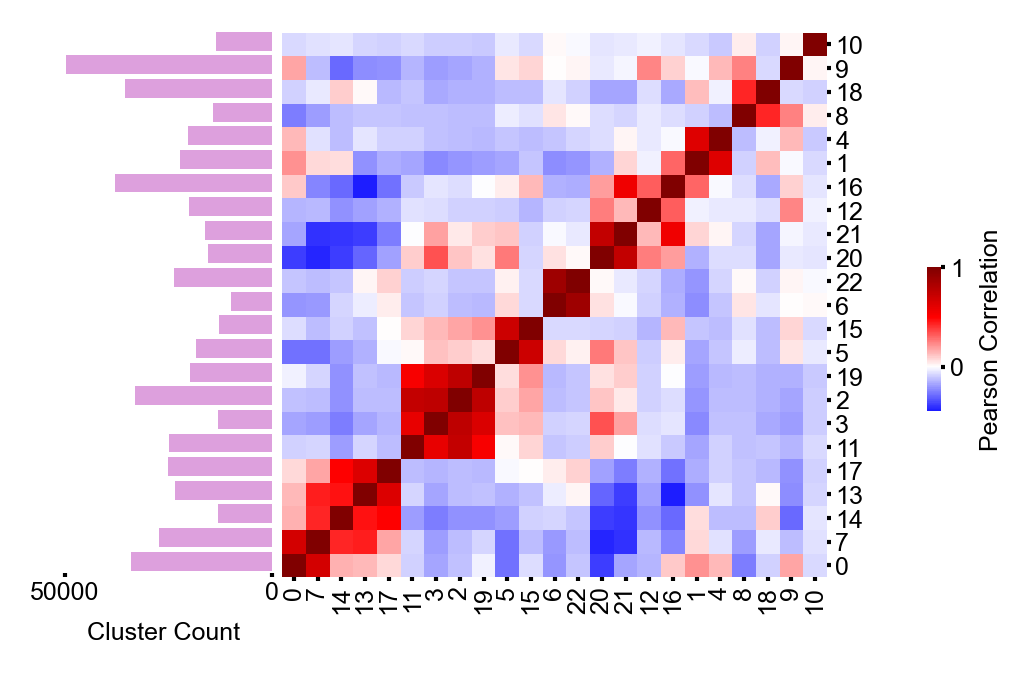

In [67]:
corr_df = roi_counts[list(range(CC_NB_OF_CLUSTERS))].corr()
#corr_df.index.name = 'Cellohood Neighborhood Cluster'
#corr_df.columns.name = 'Cellohood Neighborhood Cluster'

#matplotlib.rcParams.update(matplotlib.rcParamsDefault)

#sns.set_context("paper", rc={"font.size": 6, "axes.titlesize":6,"axes.labelsize":6})  
#plt.rcParams['legend.title_fontsize'] = 6
#plt.rcParams['legend.fontsize'] = 6
#matplotlib.rcParams['font.family'] = 'Arial'


corr_cmap = sns.clustermap(
    corr_df,
    center=0,
    cmap='seismic',
    xticklabels=True,
    yticklabels=True,
    #annot=True,
    #fmt='.2f',
    #annot_kws={'size': 3},
    cbar_pos=[1.1, 0.27, 0.02, 0.2],
    cbar_kws={'label': 'Pearson Correlation'}
)

corr_cmap.ax_row_dendrogram.set_visible(False)
corr_cmap.ax_col_dendrogram.set_visible(False)
#corr_cmap.ax_cbar.set_visible(False)

barplot_ax = corr_cmap.fig.add_axes([-.11, 0.045, .3, .755], sharey=corr_cmap.ax_heatmap)
barplot_ax.barh(
    corr_cmap.data2d.columns + 0.5,
    cluster_counts[corr_cmap.data2d.columns],
    align='center',
    height=0.8,
    color='plum',
)
barplot_ax.invert_yaxis()
barplot_ax.invert_xaxis()
barplot_ax.spines['left'].set_visible(False)
barplot_ax.spines['top'].set_visible(False)
barplot_ax.spines['right'].set_visible(False)
barplot_ax.spines['bottom'].set_visible(False)
barplot_ax.yaxis.set_visible(False)
barplot_ax.set_xlabel('Cluster Count', size=6)
barplot_ax.xaxis.set_tick_params(size=1, left=True, pad=1)
barplot_ax.set_xticklabels(
    barplot_ax.get_xticklabels(), size=6, rotation=0
)

corr_cmap.ax_cbar.tick_params(labelsize=6, size=1, pad=1)
corr_cmap.ax_row_dendrogram.set_visible(False)
corr_cmap.ax_col_dendrogram.set_visible(False)

corr_cmap.ax_heatmap.set_yticklabels(
    corr_cmap.ax_heatmap.get_yticklabels(), size=6)
corr_cmap.ax_heatmap.xaxis.set_tick_params(size=1, left=True, pad=1)
corr_cmap.ax_heatmap.yaxis.set_tick_params(size=1, pad=1, rotation=0)
corr_cmap.ax_heatmap.set_xticklabels(
    corr_cmap.ax_heatmap.get_xticklabels(), size=6, rotation=90)

corr_cmap.fig.set_dpi(PLOTTING_DPI)
corr_cmap.fig.set_size_inches((2.4, 2.4))
plt.gcf().get_size_inches()